# Germany's crude oil origins

Pulls Germany's crude oil imports by country of production from the [Fuel Origin API](https://fuelorigin.org/developers) and plots them, month by month.

**Install first:** `pip install requests pandas matplotlib` (and Jupyter, to run the notebook).

**Key:** none needed. Without a key the API answers the last 24 months; full history needs a key. If the environment variable `FO_KEY` is set, it is sent as the `X-API-Key` header.

**Requests:** two, a moment apart, one for the named partners and one for the part of each month the publisher attributes to no named partner.

The outputs saved in this file are real, from a run against the live API. The capture date is printed by the second code cell and on the chart. Want everything rather than a window? Use the [datasets](https://fuelorigin.org/datasets).

In [1]:
import os
import textwrap
import time
from datetime import date

import matplotlib.pyplot as plt
import pandas as pd
import requests

BASE_URL = "https://api.fuelorigin.org"
COUNTRY = "germany"

today = date.today()
window_start = pd.Period(today, "M") - 24   # The last 24 months: what the API answers without a key.
last_full_month = pd.Period(today, "M") - 1  # The current month is not over, so it is not drawn.

session = requests.Session()
session.headers["User-Agent"] = "fuelorigin-api-examples"
if os.environ.get("FO_KEY"):
    session.headers["X-API-Key"] = os.environ["FO_KEY"]


def crude_origins(basis):
    """One read of the route. On a refusal, print the API's reason and stop."""
    response = session.get(
        f"{BASE_URL}/api/countries/{COUNTRY}/crude-origins",
        params={"basis": basis, "from": window_start.start_time.date().isoformat(), "limit": 1000},
        timeout=120,
    )
    if response.status_code == 429:
        raise SystemExit(f"Too many requests. The API asks you to wait {response.headers.get('Retry-After')} seconds.")
    if response.status_code != 200:
        raise SystemExit(f"The API answered {response.status_code}: {response.text[:400]}")
    return response.json()


energy = crude_origins("energy")
time.sleep(1)
unknown = crude_origins("unknown")

In [2]:
source = energy["meta"]["source"]
accessed = source["retrieved_at"][:10]
print("Captured on:", today.isoformat())
print("Rows, named partners:", energy["pagination"]["total"], "| rows, no partner named:", unknown["pagination"]["total"])
print("More rows than this read holds:", energy["pagination"]["has_more"] or unknown["pagination"]["has_more"])
print("Publisher:", source["publisher"], "|", source["dataset_id"], "|", source["url"])
print("Licence as the API states it:", source["licence"])
print("Our last load of the dataset:", accessed)
window = energy["meta"].get("history_window")
if window:
    print("Without a key the answer starts at:", window["starts"])

Captured on: 2026-11-04
Rows, named partners: 475 | rows, no partner named: 16
More rows than this read holds: False
Publisher: Eurostat (European Commission) | nrg_ti_oilm | https://ec.europa.eu/eurostat/databrowser/view/nrg_ti_oilm/default/table?lang=en
Licence as the API states it: Commission Decision 2011/833/EU - reuse authorised with attribution
Our last load of the dataset: 2026-11-04
Without a key the answer starts at: 2024-11-01


## Every month, with its status

`status` comes from the API. `PARTIAL` says the named partners fall short of the month's published total; the rest is one row without a country, served on `basis=unknown`. A month with no rows at all is listed as not published, not as zero. A missing cell stays empty.

In [3]:
columns = ["period", "origin_country_name", "quantity_tonnes", "share_pct", "status", "data_class", "confidence"]
named = pd.DataFrame(energy["data"])[columns]
rest = pd.DataFrame(unknown["data"])[columns]

months = pd.period_range(window_start, last_full_month, freq="M").astype(str)
by_month = named.groupby("period")
table = pd.DataFrame(index=pd.Index(months, name="month"))
table["named_tonnes"] = by_month["quantity_tonnes"].sum(min_count=1)
table["no_partner_named_tonnes"] = rest.set_index("period")["quantity_tonnes"]
table["status"] = by_month["status"].agg(lambda s: "/".join(sorted(set(s))))
table["data_class"] = by_month["data_class"].agg(lambda s: "/".join(sorted(set(s))))
table["confidence"] = by_month["confidence"].agg(lambda s: "/".join(sorted(set(s))))
table["published"] = table["status"].notna()
print(table.to_string(na_rep="", float_format=lambda value: f"{value:,.0f}"))

         named_tonnes  no_partner_named_tonnes    status  data_class confidence  published
month                                                                                     
2024-11     6,254,042                  270,603   PARTIAL  CALCULATED   OFFICIAL       True
2024-12     6,162,727                1,090,586   PARTIAL  CALCULATED   OFFICIAL       True
2025-01     6,494,315                  505,635   PARTIAL  CALCULATED   OFFICIAL       True
2025-02     5,028,157                  983,847   PARTIAL  CALCULATED   OFFICIAL       True
2025-03     5,502,513                  582,913   PARTIAL  CALCULATED   OFFICIAL       True
2025-04     6,066,790                  507,259   PARTIAL  CALCULATED   OFFICIAL       True
2025-05     6,449,437                  502,427   PARTIAL  CALCULATED   OFFICIAL       True
2025-06     6,475,977                  354,079   PARTIAL  CALCULATED   OFFICIAL       True
2025-07     6,495,691                  492,763   PARTIAL  CALCULATED   OFFICIAL       True

## The chart

The five largest origins over the window keep their own colour; every other named partner is grey; the part with no partner named is hatched. Bars are solid: the data class and confidence the API states are in the chart's subtitle, and the status row under the bars says whether the month's named partners reach its published total.

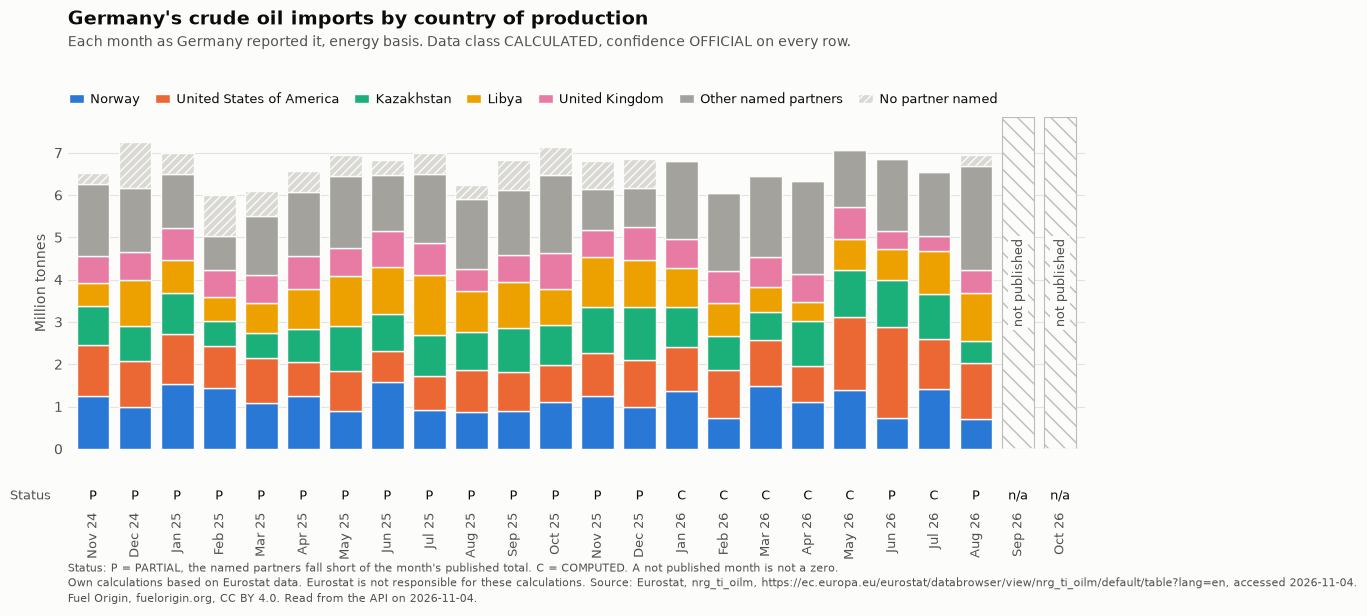

In [4]:
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
OTHER, NO_PARTNER = "#a3a29c", "#d9d8d3"

top = named.groupby("origin_country_name")["quantity_tonnes"].sum().nlargest(len(COLOURS)).index.tolist()
wide = named.pivot_table(index="period", columns="origin_country_name", values="quantity_tonnes", aggfunc="sum", min_count=1)
wide = wide.reindex(months)
stack = wide[top].copy()
stack["Other named partners"] = wide.drop(columns=top).sum(axis=1, min_count=1)
stack["No partner named"] = table["no_partner_named_tonnes"]

fig, (ax, strip) = plt.subplots(
    2, 1, figsize=(11, 6.2), dpi=100, sharex=True, height_ratios=[14, 1], facecolor=SURFACE,
    gridspec_kw={"hspace": 0.2, "left": 0.06, "right": 0.985, "top": 0.8, "bottom": 0.17},
)
ax.set_facecolor(SURFACE)
strip.set_facecolor(SURFACE)
x = range(len(months))
bottom = pd.Series(0.0, index=stack.index)
for name, colour in zip(stack.columns, COLOURS + [OTHER, NO_PARTNER]):
    values = stack[name].fillna(0) / 1e6  # Only for stacking: a month with no rows is drawn as a band below.
    ax.bar(x, values, bottom=bottom, width=0.78, color=colour, edgecolor=SURFACE, linewidth=1, label=name,
           hatch="////" if name == "No partner named" else None, zorder=3)
    bottom += values

height = bottom.max() * 1.08
for position, month in enumerate(months):
    if not table.loc[month, "published"]:
        ax.bar(position, height, width=0.78, color=SURFACE, edgecolor="#bdbcb6", linewidth=0.8, hatch="\\\\", zorder=2)
        ax.text(position, height / 2, "not published", rotation=90, ha="center", va="center", color=MUTED, fontsize=9,
                zorder=4, bbox={"facecolor": SURFACE, "edgecolor": "none", "pad": 2})

ax.set_ylim(0, height)
ax.set_xlim(-0.6, len(months) - 0.4)
ax.set_ylabel("Million tonnes", color=MUTED)
ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
ax.tick_params(axis="both", colors=MUTED, length=0)
for side in ("top", "right", "left", "bottom"):
    ax.spines[side].set_visible(False)
ax.legend(ncols=7, frameon=False, loc="lower left", bbox_to_anchor=(-0.01, 1.0), fontsize=9, labelcolor=INK,
          handlelength=1.2, columnspacing=1.2, handletextpad=0.5)

SHORT = {"PARTIAL": "P", "COMPUTED": "C"}
strip.set_ylim(0, 1)
strip.set_yticks([])
for side in ("top", "right", "left", "bottom"):
    strip.spines[side].set_visible(False)
for position, month in enumerate(months):
    status = table.loc[month, "status"]
    strip.text(position, 0.5, "n/a" if pd.isna(status) else SHORT.get(status, status), ha="center", va="center", fontsize=9, color=INK)
strip.text(-1.0, 0.5, "Status", ha="right", va="center", fontsize=9, color=MUTED)
strip.set_xticks(list(x))
strip.set_xticklabels([pd.Period(m).strftime("%b %y") for m in months], rotation=90, fontsize=9, color=MUTED)
strip.tick_params(axis="x", length=0)

classes = sorted(set(named["data_class"]) | set(rest["data_class"]))
confidences = sorted(set(named["confidence"]) | set(rest["confidence"]))
fig.text(0.06, 0.95, "Germany's crude oil imports by country of production", fontsize=14, color=INK, weight="bold")
fig.text(0.06, 0.915, f"Each month as Germany reported it, energy basis. Data class {', '.join(classes)}, confidence "
                      f"{', '.join(confidences)} on every row.", fontsize=10, color=MUTED)
note = (
    "Status: P = PARTIAL, the named partners fall short of the month's published total. C = COMPUTED. "
    "A not published month is not a zero.\n"
    "Own calculations based on Eurostat data. Eurostat is not responsible for these calculations. "
    f"Source: Eurostat, {source['dataset_id']}, {source['url']}, accessed {accessed}.\n"
    f"Fuel Origin, fuelorigin.org, CC BY 4.0. Read from the API on {today.isoformat()}."
)
fig.text(0.06, 0.012, note, fontsize=7.8, color=MUTED, va="bottom", linespacing=1.4)
plt.show()

## How to credit this

For figures calculated from Eurostat data the wording is `Own calculations based on Eurostat data.`, with Eurostat cited as the original source: the dataset code, its link and the access date, as on the chart. Eurostat is not responsible for these calculations. Fuel Origin's own output is CC BY 4.0: credit Fuel Origin, link to the page and to the licence, and say if you changed anything. Each row of the API's answer names its source, and data from another publisher stays under that publisher's licence.

- How the figures are made: <https://fuelorigin.org/methodology>
- The API: <https://fuelorigin.org/developers>
- Everything as files, with a DOI: <https://fuelorigin.org/datasets>